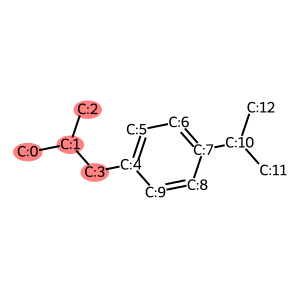

In [17]:
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import rdmolops
from rdkit.Chem import Descriptors
from rdkit.Chem import AllChem

def draw_highlighted_atoms(mol, atom_ids):
    
    for i, atom in enumerate(mol.GetAtoms()):
        # For each atom, set the property "molAtomMapNumber" to a custom number, let's say, the index of the atom in the molecule
        atom.SetProp("molAtomMapNumber", str(atom.GetIdx()))
    
    # Create a list of atom indices to highlight
    highlight_atoms = set(atom_ids)

    # Generate image with highlighted atoms
    img = Draw.MolToImage(mol, highlightAtoms=highlight_atoms, size=(300, 300))

    return img

# Example usage
smiles = 'CC(C)CC1=CC=C(C=C1)C(C)C'  # Target molecule
mol = Chem.MolFromSmiles(smiles)

# List of atom indices to highlight
atom_ids = [0, 1, 2, 3]

# Draw the molecule with highlighted atoms
highlighted_image = draw_highlighted_atoms(mol, atom_ids)
highlighted_image.show()  # This will display the image

In [18]:
#https://www.rdkit.org/docs/GettingStartedInPython.html#atom-map-indices-in-smarts
qmol = Chem.MolFromSmarts( '[cH0:1][c:2]([cH0])!@[CX3!r:3]=[NX2!r:4]' )
ind_map = {}
for atom in qmol.GetAtoms() :
    map_num = atom.GetAtomMapNum()
    if map_num:
        ind_map[map_num-1] = atom.GetIdx()
ind_map

{0: 0, 1: 1, 2: 3, 3: 4}

In [19]:
map_list = [ind_map[x] for x in sorted(ind_map)]

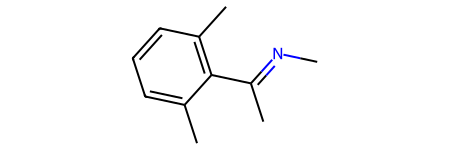

In [20]:
mol = Chem.MolFromSmiles('Cc1cccc(C)c1C(C)=NC')
mol

In [21]:
for match in mol.GetSubstructMatches( qmol ) :
    mas = [match[x] for x in map_list]
    print(mas)

[1, 7, 8, 10]


In [22]:
def extract_substructure(mol, atom_ids, use_smarts = True):
    # Create an empty molecule and add only the atoms of interest
    new_mol = Chem.RWMol()

    # Add atoms that are in the atom_ids list to the new molecule
    atom_map = {}
    for atom_idx in atom_ids:
        atom = mol.GetAtomWithIdx(atom_idx)
        new_atom_idx = new_mol.AddAtom(atom)
        atom_map[atom_idx] = new_atom_idx

    # Now we add the bonds that correspond to the atoms in atom_ids
    for bond in mol.GetBonds():
        idx1 = bond.GetBeginAtomIdx()
        idx2 = bond.GetEndAtomIdx()

        # Check if both atoms are in the atom_ids list, if so, add the bond
        if idx1 in atom_ids and idx2 in atom_ids:
            new_mol.AddBond(atom_map[idx1], atom_map[idx2], bond.GetBondType())
        elif idx1 in atom_ids or idx2 in atom_ids:
            dummy_atm = AllChem.Atom(0)
            if idx1 in atom_ids:
                new_mol.AddAtom(dummy_atm)
                new_mol.AddBond(atom_map[idx1], new_mol.GetNumAtoms() - 1, bond.GetBondType())
                new_mol.GetAtomWithIdx(atom_map[idx1]).GetImplicitValence()
                new_mol.GetAtomWithIdx(atom_map[idx1]).SetNumExplicitHs(0)
                new_mol.GetAtomWithIdx(atom_map[idx1]).SetNoImplicit(False)
                new_mol.GetAtomWithIdx(atom_map[idx1]).SetNoImplicit(False)
            else:
                new_mol.AddAtom(dummy_atm)
                new_mol.AddBond(atom_map[idx2], new_mol.GetNumAtoms() - 1, bond.GetBondType())
                new_mol.GetAtomWithIdx(atom_map[idx2]).GetImplicitValence()
                new_mol.GetAtomWithIdx(atom_map[idx2]).SetNumExplicitHs(0)
                new_mol.GetAtomWithIdx(atom_map[idx2]).SetNoImplicit(False)

    # Get the substructure as a SMILES string
    #rdmolops.SetAromaticity(new_mol)
    #Chem.SanitizeMol(new_mol, Chem.rdmolops.SanitizeFlags.SANITIZE_ALL)
    new_mol.UpdatePropertyCache()
    mw = Descriptors.ExactMolWt(new_mol)
    
    #https://www.rdkit.org/docs/GettingStartedInPython.html#atom-map-indices-in-smarts
    for i, atom in enumerate(new_mol.GetAtoms()):
        # For each atom, set the property "molAtomMapNumber" to a custom number, let's say, the index of the atom in the molecule
        if atom.GetAtomicNum() != 0:
            atom.SetProp("molAtomMapNumber", str(atom.GetIdx()+1))
    if use_smarts:
        substructure_query = Chem.MolToSmarts(new_mol)
        substructure_query = substructure_query.replace("#0","!#1")
        query_type = "SMARTS"
    else:
        substructure_query = Chem.MolToSmiles(new_mol)
        query_type = "SMILES"
    print(f"Substructure {query_type}: {substructure_query}")
    print(f"Substructure base mass: {mw}")
    return substructure_query

def match_smart_substructure(target_smiles, substructure_smiles):
    print("Target SMILES:", target_smiles)
    print("Substructure SMARTS:", substructure_smiles)
    target_mol = Chem.MolFromSmiles(target_smiles)
    #Chem.SanitizeMol(target_mol)
    qmol = Chem.MolFromSmarts(substructure_smiles)


    ind_map = {}
    for atom in qmol.GetAtoms() :
        map_num = atom.GetAtomMapNum()
        if map_num:
            ind_map[map_num-1] = atom.GetIdx()
    
    for atom in qmol.GetAtoms() :
        map_num = atom.GetAtomMapNum()
        if map_num:
            ind_map[map_num-1] = atom.GetIdx()
        
    map_list = [ind_map[x] for x in sorted(ind_map)]
    matches = []
    for match in target_mol.GetSubstructMatches( qmol ) :
        mas = [match[x] for x in map_list]
        matches.append(mas)
    
    return matches

Substructure SMARTS: [#6:1]-[#6:2](-[#6:3])-[#6:4]-[!#1]
Substructure base mass: 57.070425287999996
Substructure SMARTS: [#6:1]-[#6:2](-[#6:3])-[#6:4]-[!#1]


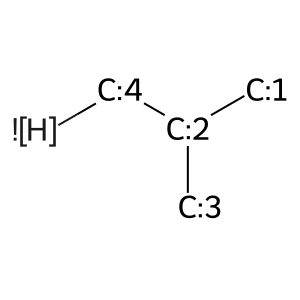

Target SMILES: CC(C)CC1=CC=C(C=C1)C(C)C
Substructure SMARTS: [#6:1]-[#6:2](-[#6:3])-[#6:4]-[!#1]
Substructure Matches: [[0, 1, 2, 3]]


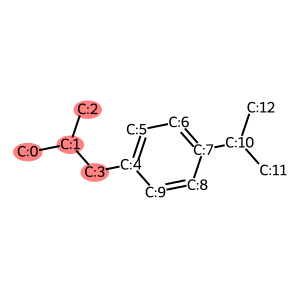

In [23]:
# Example usage
target_smiles = 'CC(C)CC1=CC=C(C=C1)C(C)C'  # Target molecule
mol = Chem.MolFromSmiles(target_smiles)
# Kekulize the molecule (convert aromatic bonds to single and double bonds)
#Chem.Kekulize(mol, clearAromaticFlags=True)
# Optionally, sanitize the molecule
# Chem.SanitizeMol(mol)

# List of atom indices to form the substructure
atom_ids = [0, 1, 2, 3]

# Extract substructure from atom indices
substructure_smart = extract_substructure(mol, atom_ids)
#substructure_smart = substructure_smart.replace('[#0]', '[*]')
print("Substructure SMARTS:", substructure_smart)
sub_mol = Chem.MolFromSmarts(substructure_smart)
img = Draw.MolToImage(sub_mol,  size=(300, 300))
img.show() # This will display the image of the substructure

# Perform substructure match with the target molecule
#substructure_smart = '[#6:1]-[#6:2](-[#6:3])-[#6:4]-[*:5]'
matches = match_smart_substructure(target_smiles, substructure_smart)
print("Substructure Matches:", matches)

atom_ids = matches[0]
highlighted_image = draw_highlighted_atoms(mol, atom_ids)
highlighted_image.show()  # This will display the image

Substructure SMARTS: [#6:1](-[#6:2](-[#6:3])-[#6:4])(:[!#1]):[!#1]
Substructure base mass: 55.054775224
Substructure SMARTS: [#6:1](-[#6:2](-[#6:3])-[#6:4])(:[!#1]):[!#1]


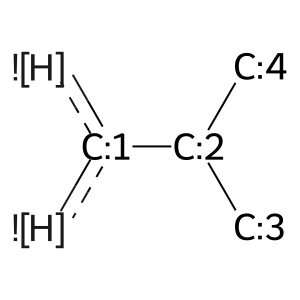

Target SMILES: CC(C)CC1=CC=C(C=C1)C(C)C
Substructure SMARTS: [#6:1](-[#6:2](-[#6:3])-[#6:4])(:[!#1]):[!#1]
Substructure Matches: [[7, 10, 11, 12]]


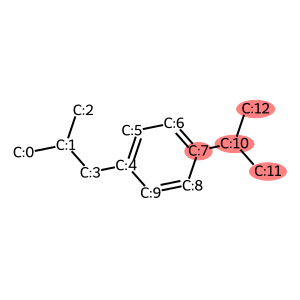

In [24]:
# Extract substructure from atom indices
atom_ids = [7, 10, 11, 12]
substructure_smart = extract_substructure(mol, atom_ids)
print("Substructure SMARTS:", substructure_smart)
sub_mol = Chem.MolFromSmarts(substructure_smart)
img = Draw.MolToImage(sub_mol,  size=(300, 300))
img.show()  # This will display the image of the substructure

# Perform substructure match with the target molecule
matches = match_smart_substructure(target_smiles, substructure_smart)
print("Substructure Matches:", matches)
if len(matches) > 0:
    atom_ids = matches[0]
    highlighted_image = draw_highlighted_atoms(mol, atom_ids)
    highlighted_image.show()  # This will display the image